<div align="center">

# Facultad de Ciencias Exactas, Ingeniería y Agrimensura
## Universidad Nacional de Rosario (UNR)

---

# Aprendizaje Automático 1
## Trabajo Práctico: Predicción de lluvia en Australia

**Integrantes:** _Cortinas Bautista, Cura Valentin, Maragliano Franco_

---
</div>

## Contenidos

1. Carga de datos y diccionario de variables
2. Análisis descriptivo
   - Limpieza inicial y fuga de datos
   - Diagnóstico y decisión sobre datos faltantes
   - Visualización: histogramas, boxplots, scatterplots
   - Balance de clases
   - Ingeniería y codificación de variables
   - Matriz de correlación
   - División train / validación / test
   - Imputación y estandarización (pipeline)
3. Regresión logística
   - Métricas, matrices de confusión, curvas ROC
   - Elección del umbral
   - Análisis del fitting
4. Modelos base

In [1]:
# Dependencias. En esta entrega alcanza con pandas, numpy, los gráficos y scikit-learn.
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    balanced_accuracy_score, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

In [2]:
# Carga del dataset. Se busca el CSV junto al notebook (repositorio clonado), después en
# la carpeta de Colab y, si no está en ninguno, se lee directo desde GitHub.
RUTAS_CSV = [
    "weatherAUS_2026C2.csv",
    "/content/sample_data/weatherAUS_2026C2.csv",
    "https://raw.githubusercontent.com/FrancoM02/AA1-TUIA-Cortinas-Cura-Maragliano/main/weatherAUS_2026C2.csv",
]
RUTA_CSV = next(r for r in RUTAS_CSV if r.startswith("http") or os.path.exists(r))

data = pd.read_csv(RUTA_CSV)
print(f"Leído desde: {RUTA_CSV}")
print(f"Filas: {data.shape[0]}   Columnas: {data.shape[1]}")

Leído desde: weatherAUS_2026C2.csv
Filas: 145412   Columnas: 25


In [3]:
# Tipos de dato y cantidad de valores no nulos por columna.
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

In [4]:
# Primeras filas, para ver el formato de cada columna.
display(data.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


## 1. Diccionario de variables

Cada fila es la observación de **un día** en **una estación meteorológica**.

| Variable | Descripción | Tipo |
|---|---|---|
| `Unnamed: 0` | Índice de un guardado anterior del archivo | Índice |
| `Date` | Fecha de la observación | Fecha |
| `Location` | Ciudad / estación donde se tomó la medición (49 en total) | Categórica |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima del día (°C) | Numérica |
| `Rainfall` | Lluvia caída en el día (mm) | Numérica |
| `Evaporation` | Evaporación en tanque tipo A en las 24 h previas a las 9 am (mm) | Numérica |
| `Sunshine` | Horas de sol brillante en el día | Numérica |
| `WindGustDir` | Dirección de la ráfaga más fuerte del día (16 rumbos) | Categórica |
| `WindGustSpeed` | Velocidad de esa ráfaga (km/h) | Numérica |
| `WindDir9am`, `WindDir3pm` | Dirección del viento a las 9 am y a las 3 pm | Categórica |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad media del viento en los 10 min previos a cada hora (km/h) | Numérica |
| `Humidity9am`, `Humidity3pm` | Humedad relativa (%) | Numérica |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica reducida al nivel del mar (hPa) | Numérica |
| `Cloud9am`, `Cloud3pm` | Fracción del cielo cubierta por nubes, en octavos (0 = despejado, 8 = cubierto, 9 = cielo no visible, por ejemplo por niebla) | Numérica discreta |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 am y a las 3 pm (°C) | Numérica |
| `RainToday` | `Yes` si hoy llovió más de 1 mm | Binaria |
| `RainTomorrow` | **Target**: `Yes` si mañana llueve más de 1 mm | Binaria |
| `RainfallTomorrow` | Lluvia caída mañana (mm) | Numérica |

## 2. Análisis descriptivo

### 2.1 Limpieza inicial y fuga de datos

El modelo va a predecir a las 23:59 de cada día. Cualquier variable que no esté
disponible a esa hora no puede entrar al modelo. `RainfallTomorrow` es justamente la
lluvia del día siguiente: no solo es información del futuro, sino que define el target.

In [5]:
# Antes de descartarla, verificamos que RainfallTomorrow determina el target: si mañana
# caen más de 1 mm, RainTomorrow es Yes. Cruzamos ambas columnas.
pd.crosstab(data["RainfallTomorrow"] > 1, data["RainTomorrow"])

RainTomorrow,No,Yes
RainfallTomorrow,,
False,110281,0
True,0,31872


El cruce confirma la relación exacta. Si dejáramos `RainfallTomorrow`, el modelo
aprendería a leer el resultado y no a predecirlo. Las métricas serían casi perfectas y
el modelo sería inútil en producción.

In [6]:
# Descartamos "Unnamed: 0" (un índice, no una medición) y RainfallTomorrow (fuga de datos).
data = data.drop(columns=["Unnamed: 0", "RainfallTomorrow"])

# Las filas sin target no sirven ni para entrenar ni para evaluar: imputar la variable a
# predecir sería inventar la respuesta.
n_antes = len(data)
data = data.dropna(subset=["RainTomorrow"]).reset_index(drop=True)
print(f"Filas sin target eliminadas: {n_antes - len(data)} ({(n_antes - len(data)) / n_antes:.1%})")
print(f"Filas restantes: {len(data)}")

# Date pasa a tipo fecha: la vamos a usar para el split temporal y para la estacionalidad.
data["Date"] = pd.to_datetime(data["Date"])
print(f"Rango de fechas: {data['Date'].min().date()} a {data['Date'].max().date()}")

Filas sin target eliminadas: 3259 (2.2%)
Filas restantes: 142153
Rango de fechas: 2007-11-01 a 2017-06-24


### 2.2 Diagnóstico de datos faltantes

In [7]:
# Faltantes por columna, en valor absoluto y en porcentaje.
faltantes = pd.DataFrame({
    "n_faltantes": data.isna().sum(),
    "pct_faltantes": (data.isna().mean() * 100).round(2),
}).sort_values("n_faltantes", ascending=False)
display(faltantes[faltantes["n_faltantes"] > 0])

,n_faltantes,pct_faltantes
Sunshine,67785,47.68
Evaporation,60812,42.78
Cloud3pm,57076,40.15
Cloud9am,53641,37.73
Pressure9am,14010,9.86
Pressure3pm,13977,9.83
WindDir9am,10009,7.04
WindGustDir,9328,6.56
WindGustSpeed,9268,6.52
WindDir3pm,3776,2.66


In [8]:
# Si descartáramos toda fila incompleta, ¿cuánto quedaría?
completas = data.dropna()
print(f"Filas completas: {len(completas)} de {len(data)} ({len(completas) / len(data):.1%})")
print(f"Ciudades que conservan al menos una fila completa: {completas['Location'].nunique()} de {data['Location'].nunique()}")

Filas completas: 56412 de 142153 (39.7%)
Ciudades que conservan al menos una fila completa: 26 de 49


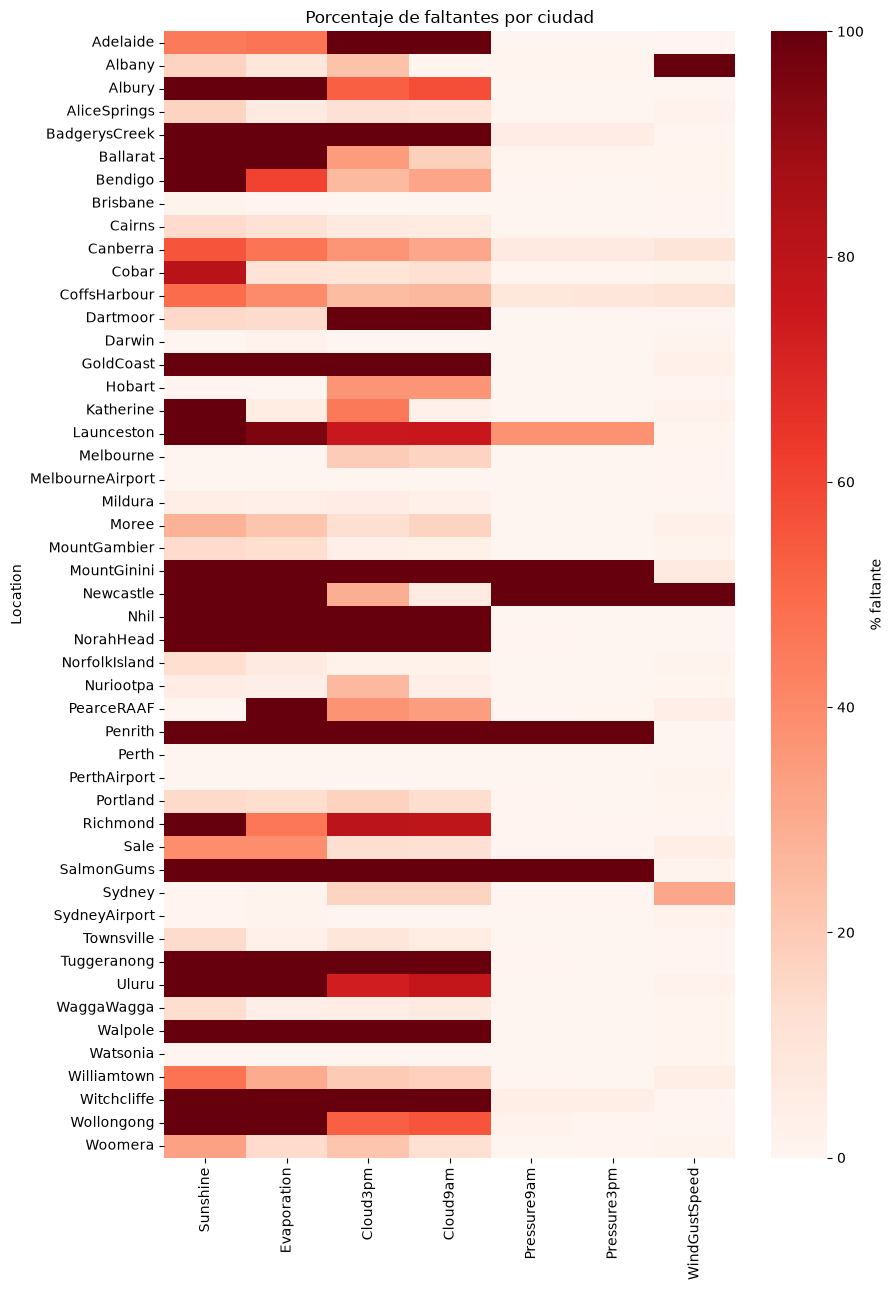

Ciudades que NUNCA registran cada variable (100% faltante):
Sunshine         19
Evaporation      16
Cloud3pm         12
Cloud9am         12
Pressure9am       4
Pressure3pm       4
WindGustSpeed     2


In [9]:
# Porcentaje de faltantes por ciudad en las variables más incompletas. Si la faltancia se
# concentra en algunas estaciones no es azar: esas estaciones directamente no miden la variable.
cols_incompletas = ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am", "Pressure9am", "Pressure3pm", "WindGustSpeed"]
falt_ciudad = data[cols_incompletas].isna().groupby(data["Location"]).mean() * 100

plt.figure(figsize=(9, 13))
sns.heatmap(falt_ciudad, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% faltante"})
plt.title("Porcentaje de faltantes por ciudad")
plt.tight_layout()
plt.show()

print("Ciudades que NUNCA registran cada variable (100% faltante):")
print((falt_ciudad == 100).sum().to_string())

### 2.3 Decisión sobre los datos faltantes

El diagnóstico muestra tres cosas:

- **Descartar filas no es una opción.** Solo el 39.7% de las filas está completa, y esas
  filas son de 26 de las 49 ciudades. Eliminar las incompletas tiraría el 60% de los datos
  y sacaría del dataset a casi la mitad de las ciudades, con lo que el modelo quedaría
  sesgado hacia las estaciones mejor equipadas.
- **La faltancia no es al azar.** En `Sunshine`, `Evaporation` y `Cloud`, el faltante
  depende de la estación: 19 ciudades nunca registran `Sunshine` y 16 nunca registran
  `Evaporation`. Son estaciones que no tienen el instrumento.
- **Las variables más incompletas están entre las más informativas.** `Sunshine` y
  `Cloud3pm` son, junto con `Humidity3pm`, las de mayor correlación con el target (ver
  2.7). Descartar esas columnas perdería justamente la mejor información.

**Decisión:**

1. Se conservan todas las filas y todas las columnas.
2. Las numéricas se imputan con la **mediana**, que es robusta a las colas largas de
   `Rainfall` y `Evaporation`, y se agrega un **indicador de faltante** por variable. El
   indicador le permite al modelo distinguir un valor medido de uno imputado. Esto importa
   cuando el faltante depende de la estación.
3. Las direcciones del viento y `RainToday` se pasan primero a números (2.6) y sus
   faltantes se resuelven de la misma forma.
4. La imputación se ajusta **solo con train** (2.9). Calcular la mediana con todo el
   dataset filtraría información del conjunto de prueba.

Una alternativa sería imputar con la mediana de cada ciudad. No resuelve el caso
principal, que son las estaciones que nunca miden la variable. Por eso preferimos la
mediana global con el indicador.

### 2.4 Visualización de las variables

In [10]:
# Resumen estadístico de las variables numéricas: rango, centro y dispersión.
display(data.describe().T.round(2))

,count,mean,min,25%,50%,75%,max,std
Date,142153,2013-03-31 14:02:26.124246,2007-11-01 00:00:00,2011-01-05 00:00:00,2013-05-27 00:00:00,2015-06-12 00:00:00,2017-06-24 00:00:00,NaN
MinTemp,141516.0,12.188866,-9.7,7.6,12.0,16.8,34.1,6.422856
MaxTemp,141831.0,23.228596,-5.1,17.9,22.6,28.2,49.1,7.134436
Rainfall,140747.0,2.350461,0.0,0.0,0.0,0.8,371.0,8.466267
Evaporation,81341.0,5.470149,0.0,2.6,4.8,7.4,145.0,4.188649
Sunshine,74368.0,7.624919,0.0,4.9,8.5,10.6,14.5,3.781656
WindGustSpeed,132885.0,39.985807,6.0,31.0,38.0,48.0,135.0,13.630314
WindSpeed9am,140805.0,14.025219,0.0,7.0,13.0,19.0,130.0,8.914326
WindSpeed3pm,139524.0,18.636901,0.0,12.0,18.0,24.0,86.0,8.858849
Humidity9am,140379.0,68.824619,0.0,56.9,69.9,83.1,100.0,19.085026


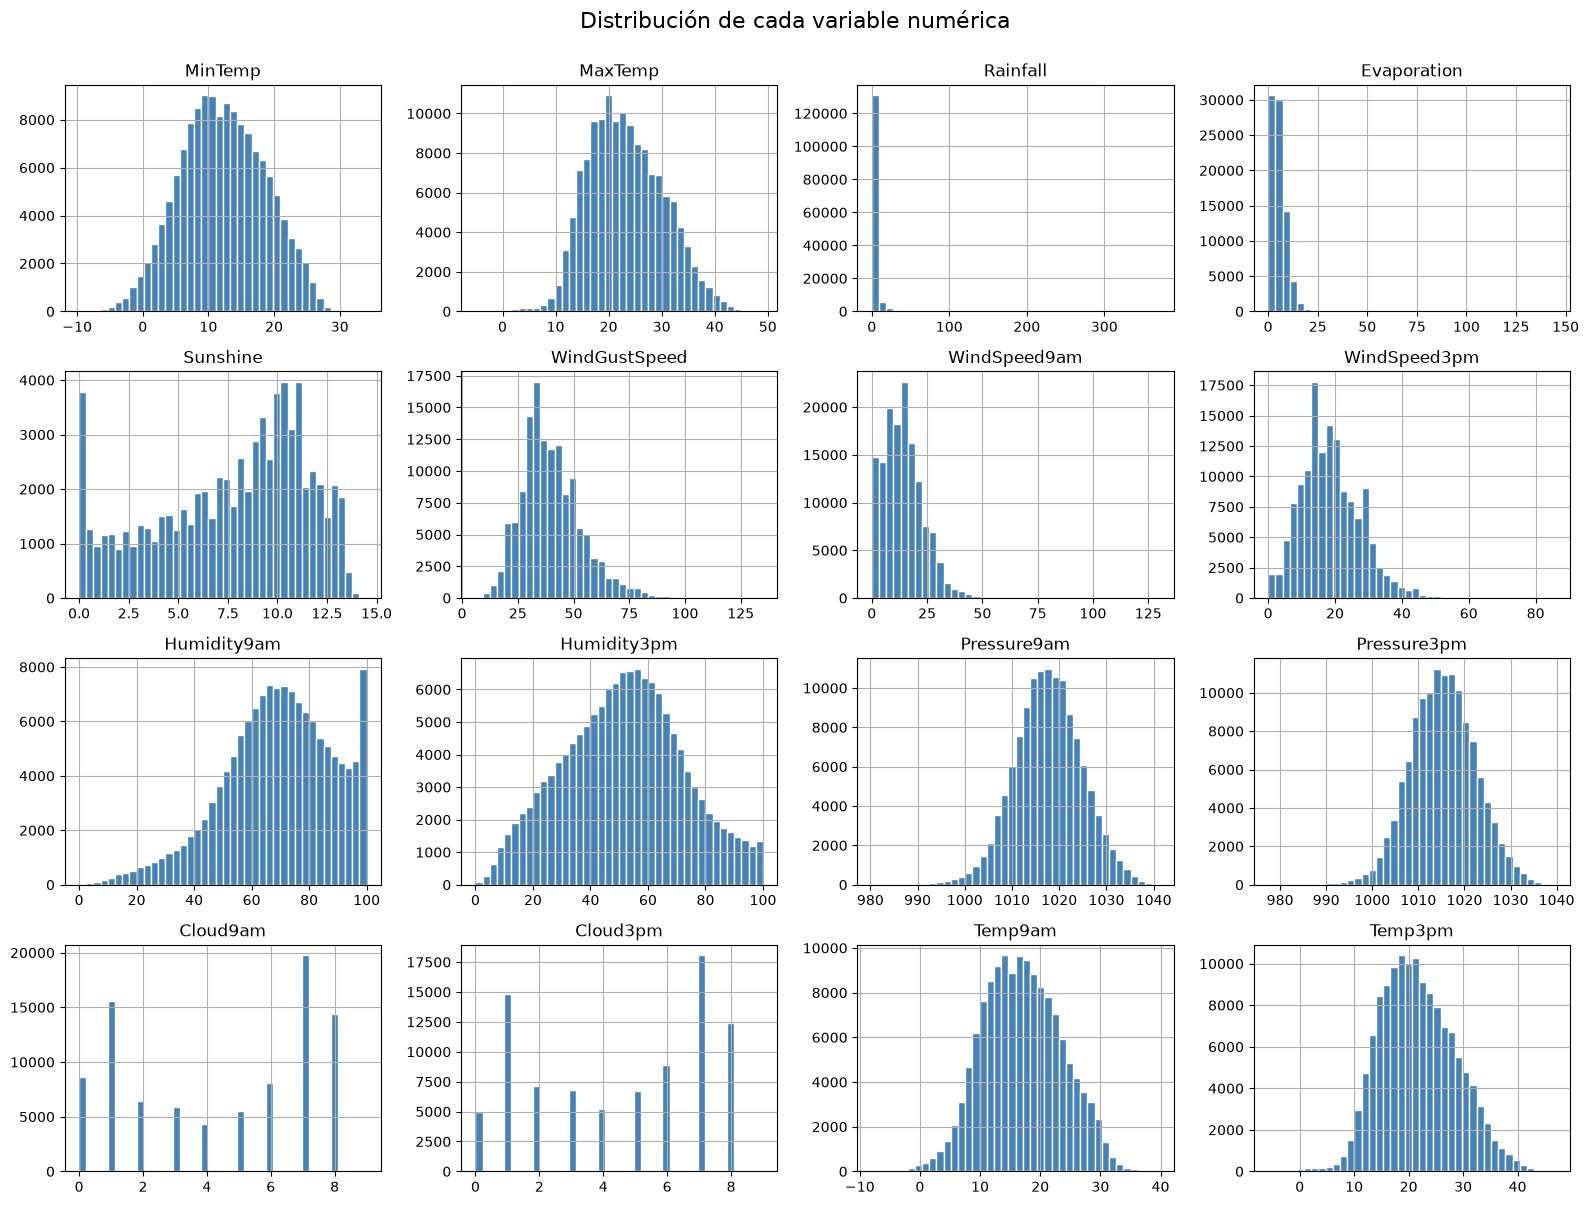

In [11]:
# Histogramas: forma de la distribución de cada variable numérica.
num_originales = data.select_dtypes("number").columns
data[num_originales].hist(bins=40, figsize=(16, 12), color="steelblue", edgecolor="white")
plt.suptitle("Distribución de cada variable numérica", fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

In [12]:
# Rainfall y Evaporation tienen una cola muy larga. Medimos qué parte de los días no llueve
# y la asimetría de cada variable.
print(f"Días con Rainfall = 0: {(data['Rainfall'] == 0).mean():.1%}")
print()
print("Coeficiente de asimetría (skewness):")
print(data[num_originales].skew().sort_values(ascending=False).round(2).to_string())

Días con Rainfall = 0: 63.5%

Coeficiente de asimetría (skewness):
Rainfall         9.89
Evaporation      3.75
WindGustSpeed    0.87
WindSpeed9am     0.79
WindSpeed3pm     0.62
Temp3pm          0.24
MaxTemp          0.22
Temp9am          0.09
Humidity3pm      0.03
MinTemp          0.02
Pressure3pm     -0.05
Pressure9am     -0.10
Cloud3pm        -0.22
Cloud9am        -0.22
Humidity9am     -0.48
Sunshine        -0.50


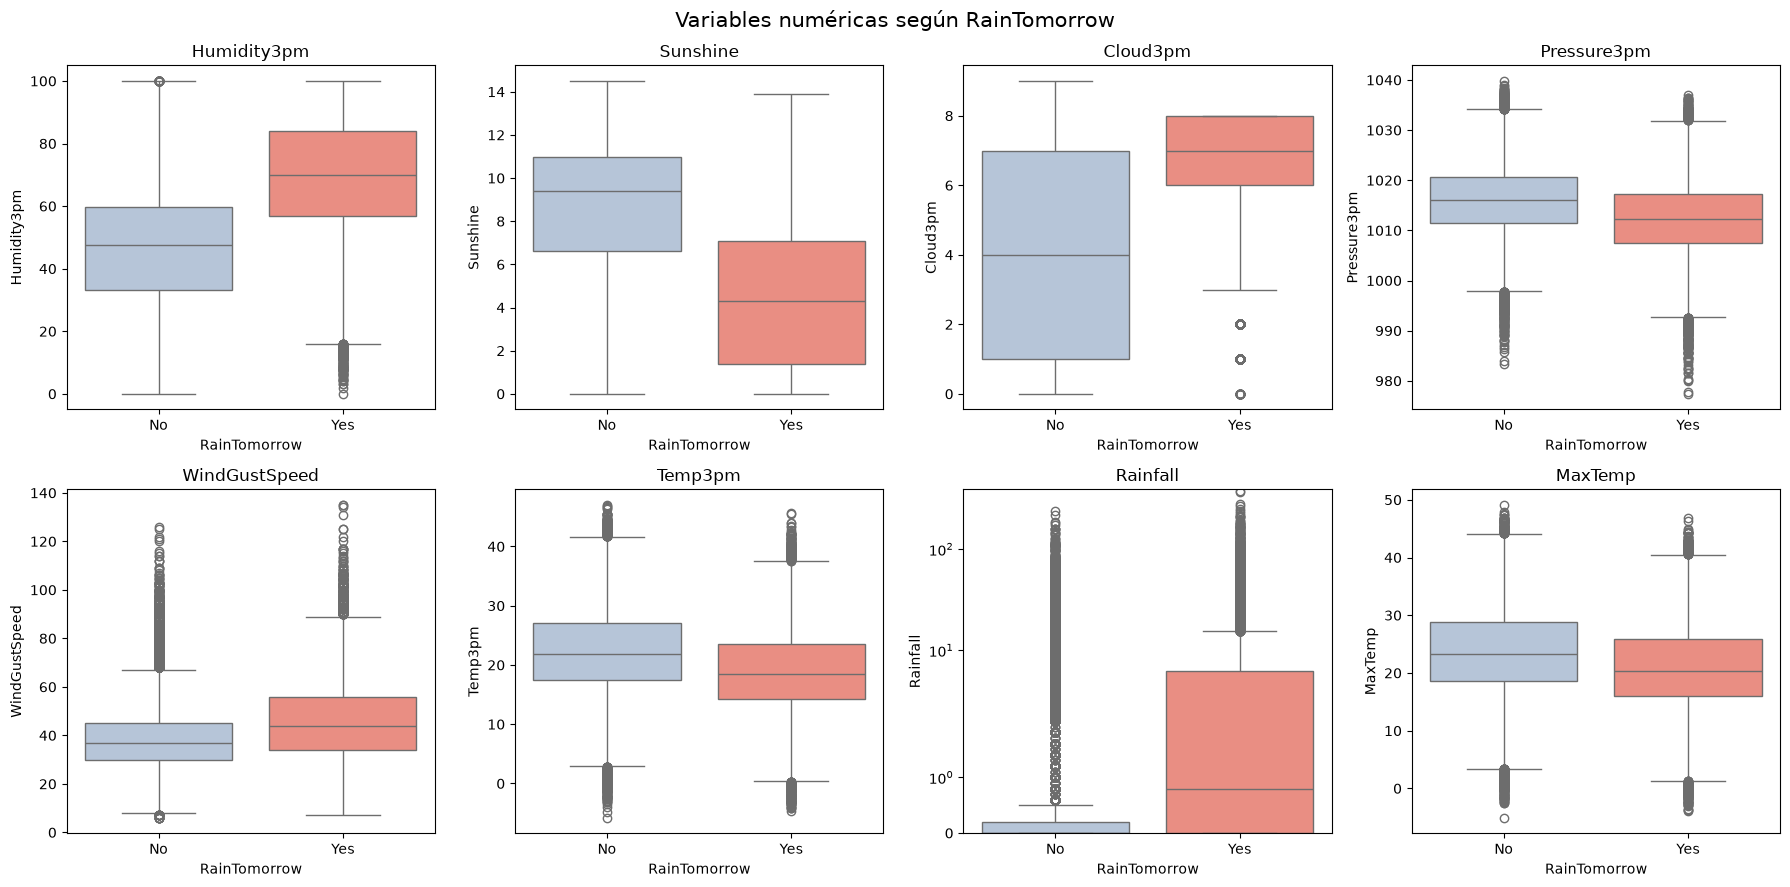

In [13]:
# Diagramas de caja separados por el target. Para un problema de clasificación lo que
# interesa es qué variables se comportan distinto el día previo a una lluvia.
cols_box = ["Humidity3pm", "Sunshine", "Cloud3pm", "Pressure3pm",
            "WindGustSpeed", "Temp3pm", "Rainfall", "MaxTemp"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cols_box):
    sns.boxplot(data=data, x="RainTomorrow", y=col, ax=ax, hue="RainTomorrow",
                palette={"No": "lightsteelblue", "Yes": "salmon"}, legend=False)
    ax.set_title(col)
axes[1, 2].set_yscale("symlog")  # Rainfall: escala logarítmica para que se vea la caja
axes[1, 2].set_ylim(bottom=0)
plt.suptitle("Variables numéricas según RainTomorrow", fontsize=15)
plt.tight_layout()
plt.show()

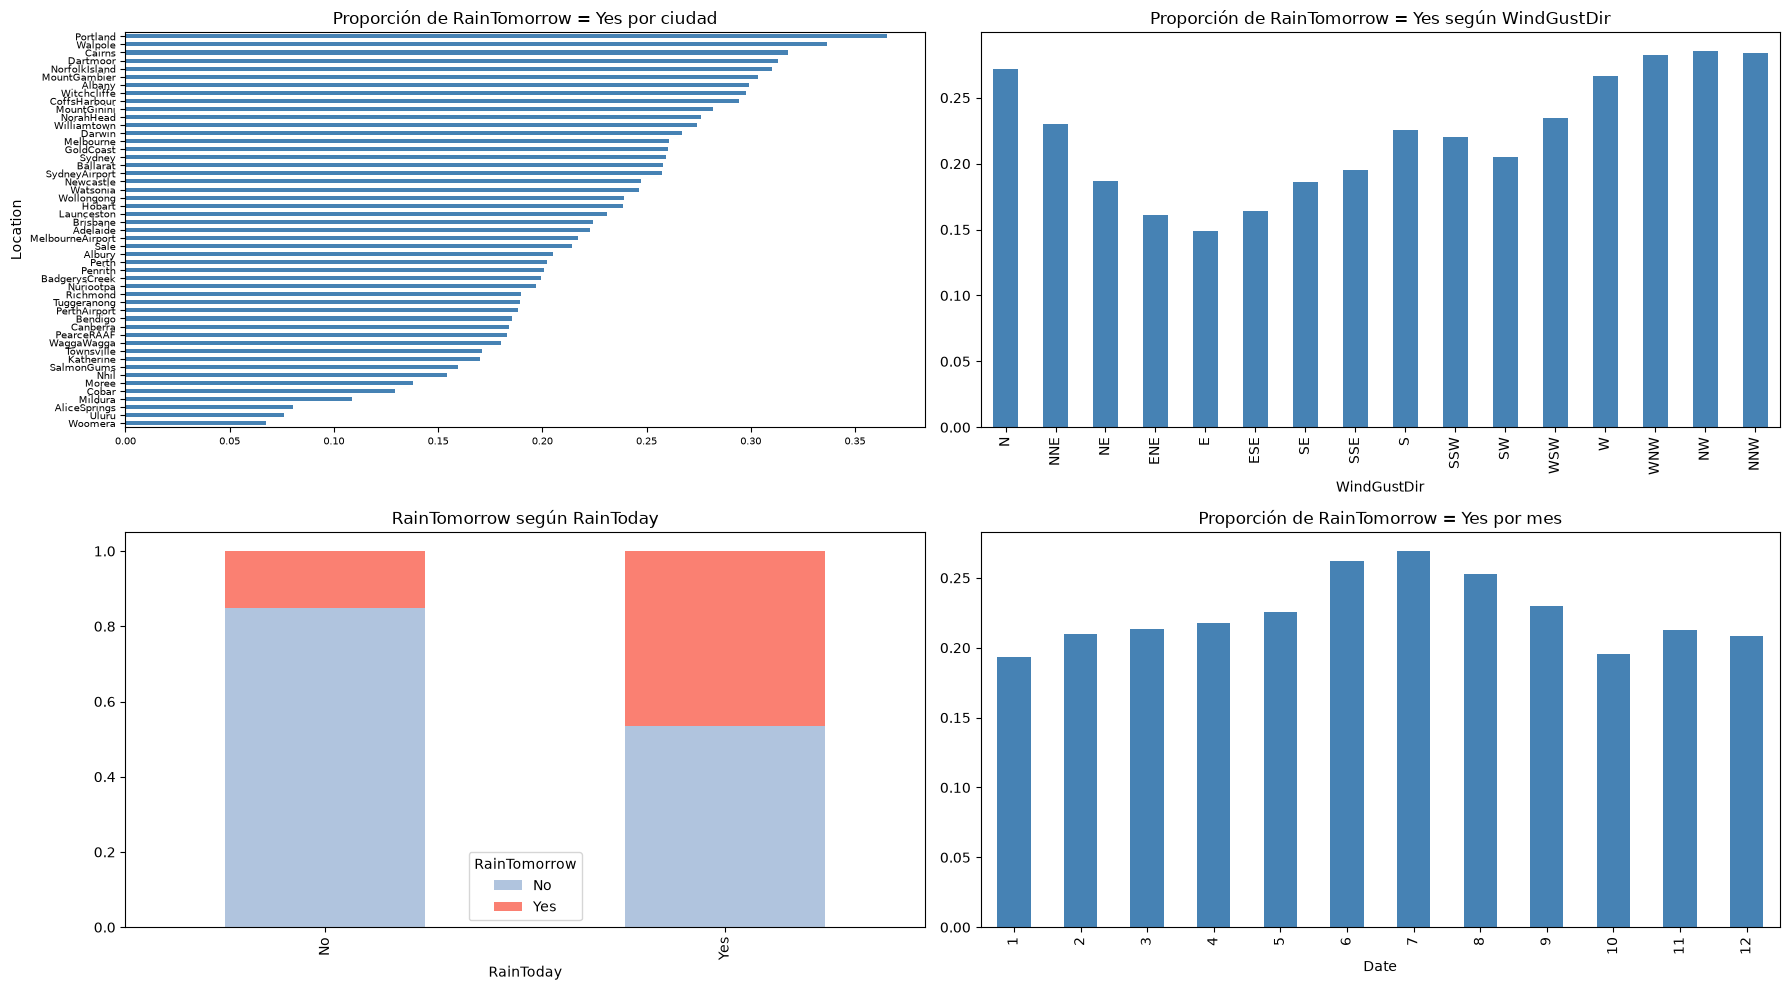

In [14]:
# Variables categóricas: proporción de días previos a lluvia para cada valor. Si la
# proporción cambia mucho entre categorías, la variable aporta información.
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

tasa_ciudad = (data["RainTomorrow"] == "Yes").groupby(data["Location"]).mean().sort_values()
tasa_ciudad.plot.barh(ax=axes[0, 0], color="steelblue", fontsize=7)
axes[0, 0].set_title("Proporción de RainTomorrow = Yes por ciudad")

orden_rumbos = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
                "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
(data["RainTomorrow"] == "Yes").groupby(data["WindGustDir"]).mean().reindex(orden_rumbos).plot.bar(
    ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Proporción de RainTomorrow = Yes según WindGustDir")

pd.crosstab(data["RainToday"], data["RainTomorrow"], normalize="index").plot.bar(
    ax=axes[1, 0], stacked=True, color=["lightsteelblue", "salmon"])
axes[1, 0].set_title("RainTomorrow según RainToday")

(data["RainTomorrow"] == "Yes").groupby(data["Date"].dt.month).mean().plot.bar(
    ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Proporción de RainTomorrow = Yes por mes")

plt.tight_layout()
plt.show()

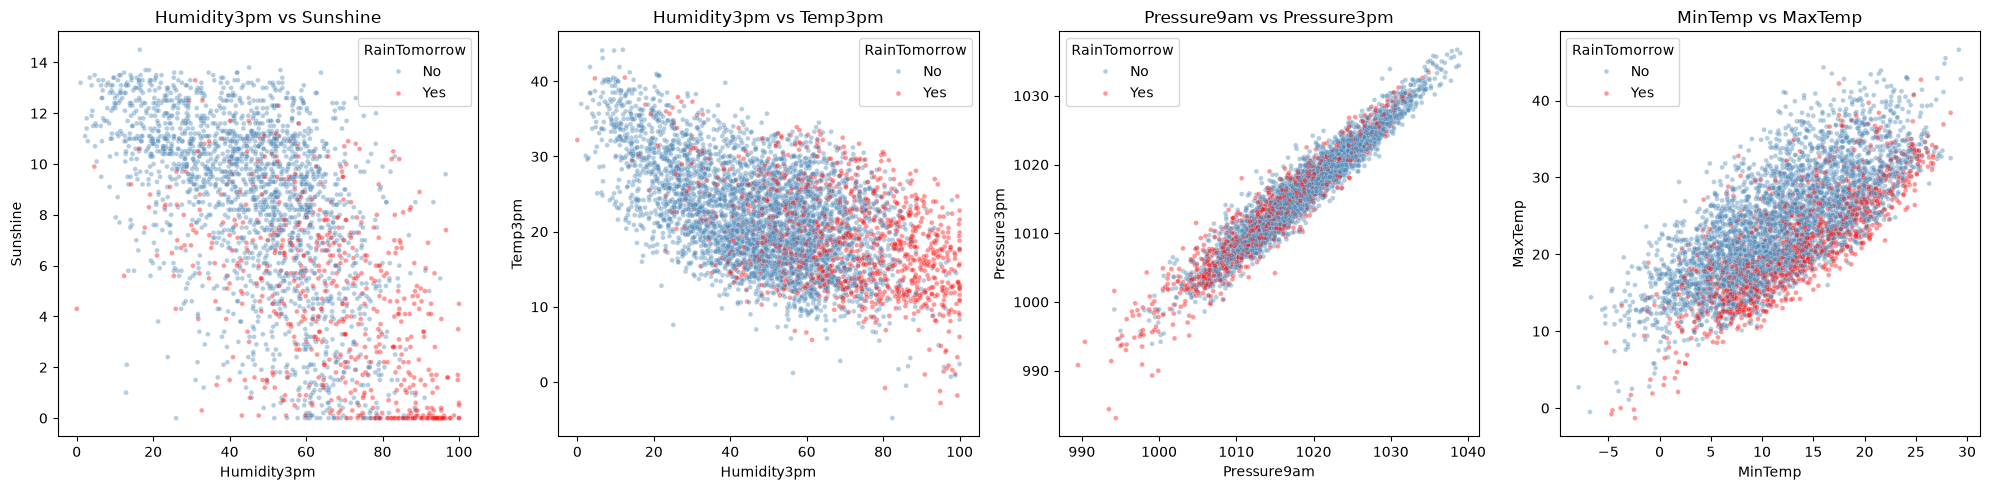

In [15]:
# Scatterplots entre pares de variables. Se usa una muestra de 5000 filas porque con 140 mil
# puntos el gráfico se satura y no se ve nada.
muestra = data.sample(5000, random_state=RANDOM_STATE)
pares = [("Humidity3pm", "Sunshine"), ("Humidity3pm", "Temp3pm"),
         ("Pressure9am", "Pressure3pm"), ("MinTemp", "MaxTemp")]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (x, y) in zip(axes, pares):
    sns.scatterplot(data=muestra, x=x, y=y, hue="RainTomorrow", alpha=0.4, s=12, ax=ax,
                    palette={"No": "steelblue", "Yes": "red"})
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()

#### Lectura de las variables

| Variable | Rango | Comportamiento |
|---|---|---|
| `MinTemp`, `MaxTemp` | -9.7 a 34.1 °C / -5.1 a 49.1 °C | Distribución aproximadamente simétrica. Los días previos a una lluvia son más frescos: la mediana de `MaxTemp` baja de 23.3 a 20.3 °C. |
| `Temp9am`, `Temp3pm` | -8.0 a 39.8 °C / -5.8 a 47.0 °C | Simétricas y casi redundantes con la mínima y la máxima (ver correlación). |
| `Rainfall` | 0 a 371 mm | Muy asimétrica (skewness 9.9): el 63.5% de los días vale 0 y unos pocos superan los 100 mm. Los valores extremos son lluvias reales, no errores, y se mantienen. |
| `Evaporation` | 0 a 145 mm | Asimétrica a la derecha. Falta en el 43% de los días. |
| `Sunshine` | 0 a 14.5 h | Asimétrica a la izquierda: la mayoría de los días son soleados. Es la variable que más se separa entre clases: mediana de 9.4 h antes de un día seco contra 4.3 h antes de un día de lluvia. |
| `WindGustSpeed` | 6 a 135 km/h | Cola a la derecha. Las ráfagas son algo más fuertes antes de un día de lluvia (mediana 44 contra 37 km/h). |
| `WindSpeed9am`, `WindSpeed3pm` | 0 a 130 km/h / 0 a 86 km/h | Cola a la derecha, con muchos días de calma (0 km/h). |
| `Humidity9am`, `Humidity3pm` | 0 a 100 % | `Humidity3pm` es casi simétrica y muy discriminante: mediana de 47.5% antes de un día seco y 70.1% antes de uno de lluvia. Hay 17 registros con humedad 0%, poco plausibles pero no imposibles en el desierto. Se mantienen. |
| `Pressure9am`, `Pressure3pm` | 980 a 1041 hPa | Casi normales. La presión baja antes de un día de lluvia (mediana 1012 contra 1016 hPa a las 3 pm), por el paso de los frentes. |
| `Cloud9am`, `Cloud3pm` | 0 a 9 octavos | Discretas y bimodales: concentradas en cielo despejado (0–1) y cubierto (7–8). El valor 9 (cielo no visible) aparece solo 3 veces. Antes de un día de lluvia la mediana de `Cloud3pm` sube de 4 a 7. |
| Direcciones del viento | 16 rumbos | Con ráfagas del NW, NNW o WNW, alrededor del 28% de los días siguientes llueve; con ráfagas del E, solo el 15%. |
| `Location` | 49 ciudades | La proporción de días con lluvia va del 7% (Woomera, en el desierto) al 37% (Portland, en la costa sur). La ubicación pesa mucho. |
| `RainToday` | Yes / No | Si hoy llovió, mañana llueve en el 46% de los casos; si no, en el 15%. |
| Mes | 1 a 12 | Estacionalidad suave: el invierno austral (junio–agosto) tiene más días de lluvia (alrededor del 26%) que el verano (19–21%). |

### 2.5 ¿Está balanceado el dataset?

                   n   pct
RainTomorrow              
No            110281  77.6
Yes            31872  22.4


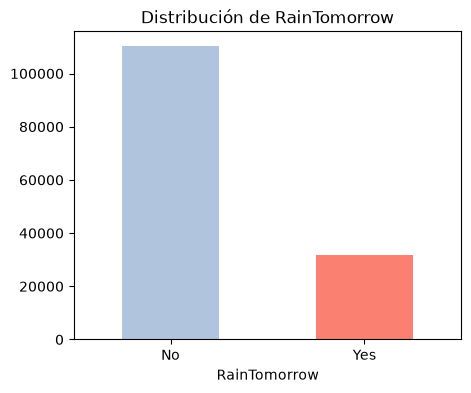

In [16]:
# Distribución del target.
conteo = data["RainTomorrow"].value_counts()
print(pd.DataFrame({"n": conteo, "pct": (conteo / len(data) * 100).round(1)}))

conteo.plot.bar(color=["lightsteelblue", "salmon"], figsize=(5, 4), rot=0)
plt.title("Distribución de RainTomorrow")
plt.show()

**No está balanceado:** el 77.6% de los días no llueve al día siguiente y el 22.4% sí, una
relación de 3.5 a 1. No es un desbalance extremo, como el de la detección de fraude, pero
alcanza para afectar tanto el entrenamiento como la evaluación.

¿Por qué importa?

- **Evaluación:** un modelo que responde siempre "no llueve" obtiene 77.6% de accuracy sin
  aprender nada. La accuracy sola no permite distinguir un modelo útil de uno trivial. Hay
  que mirar métricas por clase (recall, precision, F1) o métricas que no dependan de la
  proporción (balanced accuracy, curvas ROC y PR).
- **Entrenamiento:** la función de costo está dominada por los ejemplos de la clase
  mayoritaria, así que ante la duda el modelo tiende a predecir "no llueve". Se puede
  corregir con pesos en la función de costo (`class_weight`), con remuestreo o moviendo
  el umbral de decisión. En la sección 3 comparamos los pesos y el umbral.
- **División:** la proporción tiene que mantenerse parecida en train, validación y test
  para que las métricas sean comparables. Lo verificamos en 2.8.

### 2.6 Ingeniería y codificación de variables

- **`Location` → `Region`.** Las 49 ciudades se agrupan en 8 regiones climáticas, según
  su ubicación geográfica y su régimen de lluvias. One-hot sobre 49 ciudades agregaría 49
  columnas, varias con pocas observaciones. Además, el gráfico de proporción por ciudad
  muestra que las ciudades vecinas llueven de forma parecida.
- **Direcciones del viento → seno y coseno del ángulo.** Los 16 rumbos son una variable
  circular: N y NNW están a 22.5° de distancia, pero un código ordinal (0 y 15) los pondría
  en extremos opuestos. Con el seno y el coseno, rumbos vecinos quedan cerca. Además se
  usan 2 columnas por variable en lugar de 16.
- **Mes → seno y coseno.** El gráfico por mes muestra estacionalidad. El mes también es
  circular: diciembre está al lado de enero.
- **`RainToday` y `RainTomorrow` → 0/1.**

In [17]:
# Agrupamiento de ciudades en regiones climáticas.
REGIONES = {
    "Tropical norte": ["Darwin", "Katherine", "Cairns", "Townsville"],
    "Subtropical este": ["Brisbane", "GoldCoast", "CoffsHarbour", "NorfolkIsland"],
    "Costa NSW": ["Sydney", "SydneyAirport", "Newcastle", "NorahHead", "Williamtown",
                  "Wollongong", "Penrith", "Richmond", "BadgerysCreek"],
    "Interior árido": ["AliceSprings", "Uluru", "Woomera", "Cobar", "Mildura", "Moree", "SalmonGums"],
    "Sudeste interior": ["Canberra", "Tuggeranong", "MountGinini", "Albury", "WaggaWagga",
                         "Bendigo", "Ballarat"],
    "Sur (VIC/SA)": ["Melbourne", "MelbourneAirport", "Watsonia", "Sale", "Portland", "Dartmoor",
                     "MountGambier", "Nhil", "Adelaide", "Nuriootpa"],
    "Tasmania": ["Hobart", "Launceston"],
    "Sudoeste (WA)": ["Perth", "PerthAirport", "PearceRAAF", "Albany", "Walpole", "Witchcliffe"],
}
ciudad_a_region = {ciudad: region for region, ciudades in REGIONES.items() for ciudad in ciudades}
data["Region"] = data["Location"].map(ciudad_a_region)

# Toda ciudad tiene que tener región asignada.
assert data["Region"].notna().all(), data.loc[data["Region"].isna(), "Location"].unique()
print(data["Region"].value_counts().to_string())

Region
Sur (VIC/SA)        28066
Costa NSW           26597
Sudeste interior    21365
Interior árido      19342
Sudoeste (WA)       17745
Subtropical este    12054
Tropical norte      10770
Tasmania             6214


In [18]:
# Direcciones del viento: cada rumbo es un ángulo (N = 0°, E = 90°, ...) y se reemplaza por su
# seno y su coseno. Los faltantes quedan como NaN y los resuelve el imputador más adelante.
ANGULO = {rumbo: i * 22.5 for i, rumbo in enumerate(orden_rumbos)}
COLS_VIENTO = ["WindGustDir", "WindDir9am", "WindDir3pm"]
for col in COLS_VIENTO:
    radianes = np.deg2rad(data[col].map(ANGULO))
    data[f"{col}_sin"] = np.sin(radianes)
    data[f"{col}_cos"] = np.cos(radianes)

# Mes como variable cíclica.
mes = data["Date"].dt.month
data["Month_sin"] = np.sin(2 * np.pi * mes / 12)
data["Month_cos"] = np.cos(2 * np.pi * mes / 12)

# Binarias a 0/1. RainToday conserva sus NaN para que también los resuelva el imputador.
data["RainToday"] = data["RainToday"].map({"No": 0, "Yes": 1})
data["RainTomorrow"] = data["RainTomorrow"].map({"No": 0, "Yes": 1})

display(data[["Date", "Location", "Region", "WindGustDir", "WindGustDir_sin", "WindGustDir_cos",
              "Month_sin", "Month_cos", "RainToday", "RainTomorrow"]].head())

,Date,Location,Region,WindGustDir,WindGustDir_sin,WindGustDir_cos,Month_sin,Month_cos,RainToday,RainTomorrow
0,2008-12-01,Albury,Sudeste interior,W,-1.000000,-1.836970e-16,-2.449294e-16,1.0,0.0,0
1,2008-12-02,Albury,Sudeste interior,WNW,-0.923880,3.826834e-01,-2.449294e-16,1.0,0.0,0
2,2008-12-03,Albury,Sudeste interior,WSW,-0.923880,-3.826834e-01,-2.449294e-16,1.0,0.0,0
3,2008-12-04,Albury,Sudeste interior,NE,0.707107,7.071068e-01,-2.449294e-16,1.0,0.0,0
4,2008-12-05,Albury,Sudeste interior,W,-1.000000,-1.836970e-16,-2.449294e-16,1.0,0.0,0


### 2.7 Matriz de correlación

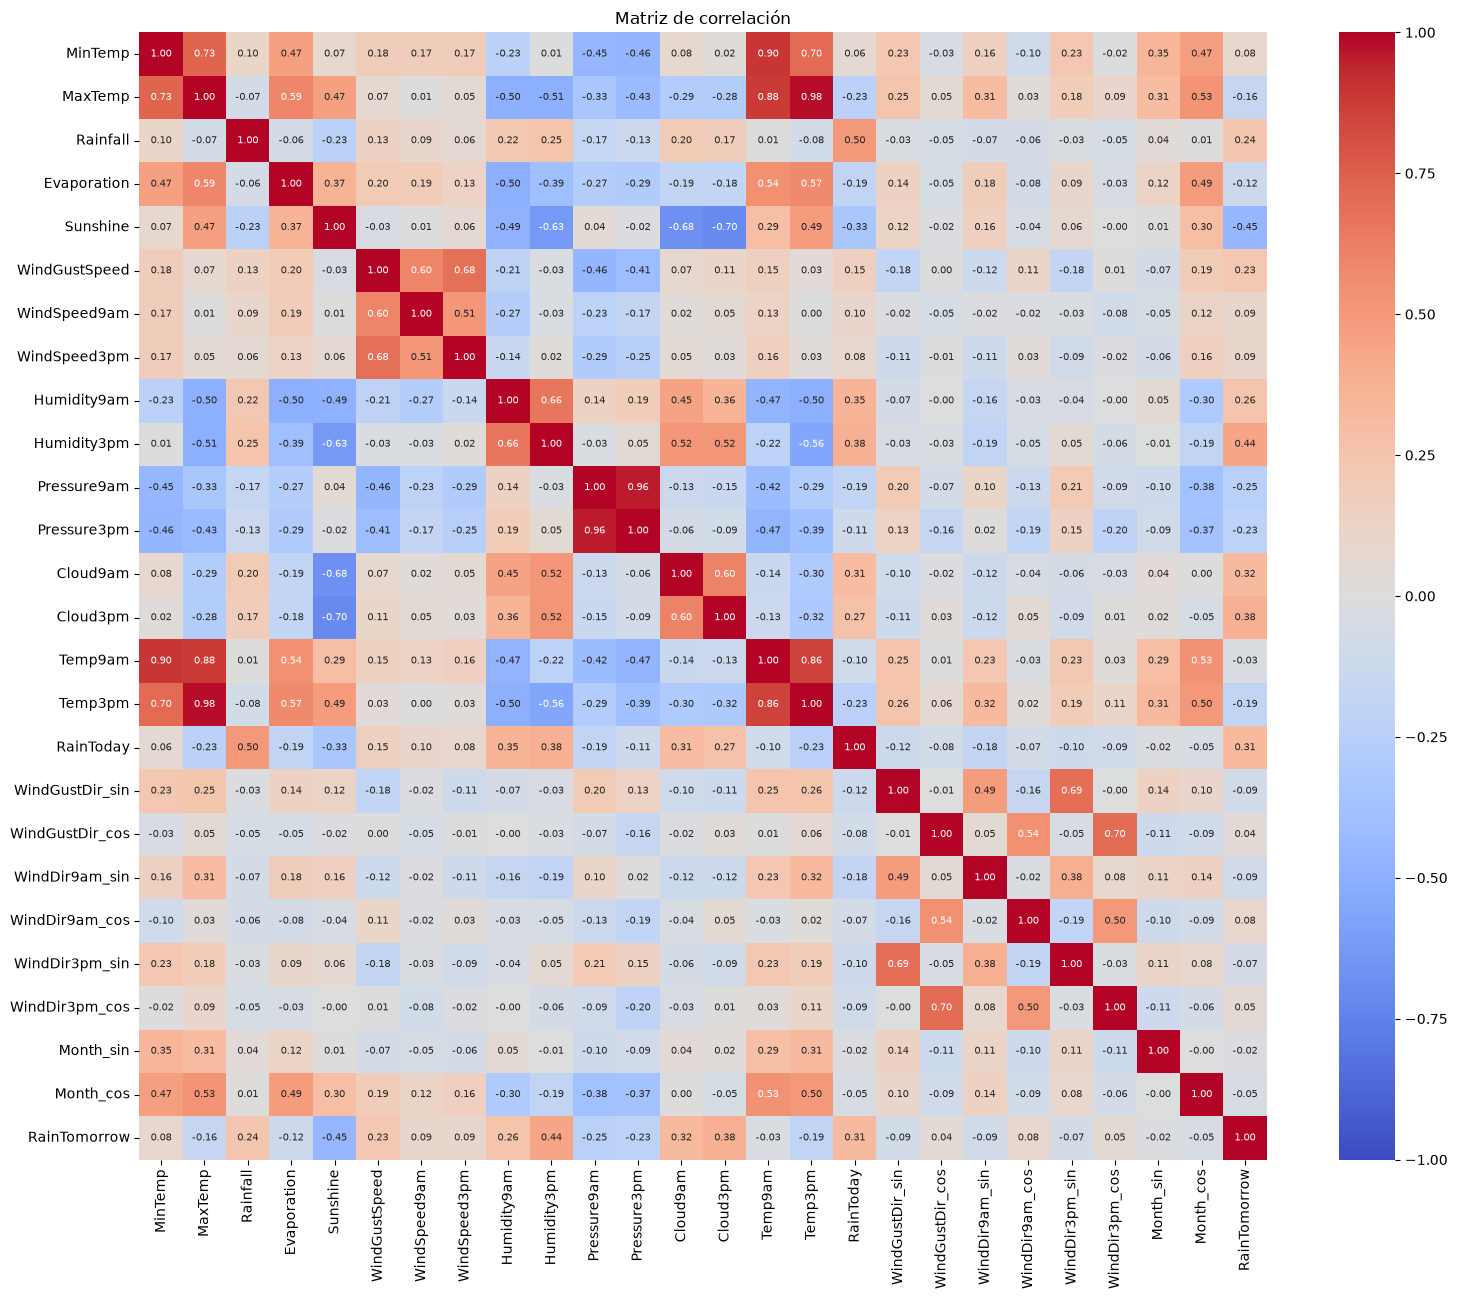

In [19]:
# Variables que entran al modelo. Location, Date y los rumbos en texto quedan afuera porque ya
# están representados por Region, Month_sin/cos y los senos y cosenos del viento.
COLS_NUM = [
    "MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", "WindGustSpeed",
    "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm", "Pressure9am",
    "Pressure3pm", "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm", "RainToday",
    "WindGustDir_sin", "WindGustDir_cos", "WindDir9am_sin", "WindDir9am_cos",
    "WindDir3pm_sin", "WindDir3pm_cos", "Month_sin", "Month_cos",
]
COLS_CAT = ["Region"]
TARGET = "RainTomorrow"

# Correlación lineal entre las variables numéricas y el target.
corr_matrix = data[COLS_NUM + [TARGET]].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, annot_kws={"size": 7})
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

In [20]:
# Correlación de cada variable con el target, ordenada por magnitud.
corr_target = corr_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Correlación con RainTomorrow:")
print(corr_target.round(3).to_string())

# Pares de predictores fuertemente correlacionados entre sí.
print("\nPares de predictores con |correlación| > 0.7:")
for i, a in enumerate(COLS_NUM):
    for b in COLS_NUM[i + 1:]:
        if abs(corr_matrix.loc[a, b]) > 0.7:
            print(f"  {a:15s} - {b:15s} {corr_matrix.loc[a, b]:.2f}")

Correlación con RainTomorrow:
Sunshine          -0.451
Humidity3pm        0.445
Cloud3pm           0.382
Cloud9am           0.317
RainToday          0.313
Humidity9am        0.256
Pressure9am       -0.246
Rainfall           0.239
WindGustSpeed      0.233
Pressure3pm       -0.226
Temp3pm           -0.192
MaxTemp           -0.159
Evaporation       -0.119
WindDir9am_sin    -0.091
WindSpeed9am       0.090
WindSpeed3pm       0.088
WindGustDir_sin   -0.086
MinTemp            0.084
WindDir9am_cos     0.082
WindDir3pm_sin    -0.068
WindDir3pm_cos     0.054
Month_cos         -0.046
WindGustDir_cos    0.044
Temp9am           -0.025
Month_sin         -0.019

Pares de predictores con |correlación| > 0.7:
  MinTemp         - MaxTemp         0.73
  MinTemp         - Temp9am         0.90
  MinTemp         - Temp3pm         0.70
  MaxTemp         - Temp9am         0.88
  MaxTemp         - Temp3pm         0.98
  Sunshine        - Cloud3pm        -0.70
  Pressure9am     - Pressure3pm     0.96
  Temp9am 

- Las variables más asociadas con la lluvia del día siguiente son **`Sunshine`** (-0.45),
  **`Humidity3pm`** (0.45), **`Cloud3pm`** (0.38) y **`RainToday`** (0.31). Coincide con
  lo que se vio en los boxplots: la tarde previa a una lluvia es húmeda, nublada y con
  poco sol.
- La presión correlaciona negativamente (-0.25 a las 9 am): la presión baja acompaña a los
  frentes de mal tiempo.
- Los senos y cosenos del viento y del mes tienen correlaciones lineales chicas (menores a
  0.1). Eso no quiere decir que no sirvan. La correlación mide solo la relación lineal de
  cada componente por separado, y el gráfico por rumbo mostró diferencias claras: 15% de
  días con lluvia con ráfagas del E contra 28% con ráfagas del NW.
- **Colinealidad:** las cuatro temperaturas están muy correlacionadas entre sí
  (`MaxTemp`–`Temp3pm` 0.98), y lo mismo pasa con las dos presiones (0.96). Para esta
  entrega las mantenemos. La regresión logística de scikit-learn aplica regularización L2
  por defecto, que reparte el peso entre variables correlacionadas en lugar de inflar los
  coeficientes. Con la optimización de hiperparámetros (ítem 4) y la explicabilidad
  (ítem 5) vamos a revisar si conviene eliminar alguna.

### 2.8 División en entrenamiento, validación y prueba

El modelo se usa para predecir **días futuros**, así que la división se hace **por fecha**
y no al azar. Con un split aleatorio, el test quedaría intercalado con el train: el modelo
vería el día 15 y el 17 de un mes y se lo evaluaría sobre el 16, cuando en producción
nunca va a tener datos posteriores al día que predice. Además, días consecutivos en una
misma ciudad se parecen mucho, y eso inflaría las métricas.

- **Entrenamiento:** hasta el 31/12/2014.
- **Validación:** 2015. Se usa para elegir el umbral, y en la próxima entrega los
  hiperparámetros.
- **Prueba:** desde el 01/01/2016. Se usa una sola vez por modelo, para la evaluación final.

La división se hace **antes** de imputar y escalar, para que ninguna estadística del
conjunto de prueba se filtre al entrenamiento.

In [21]:
# Split temporal.
train = data[data["Date"] <= "2014-12-31"]
val = data[(data["Date"] >= "2015-01-01") & (data["Date"] <= "2015-12-31")]
test = data[data["Date"] >= "2016-01-01"]

# Los tres conjuntos no se solapan en el tiempo y cubren todo el dataset.
assert train["Date"].max() < val["Date"].min() and val["Date"].max() < test["Date"].min()
assert len(train) + len(val) + len(test) == len(data)

X_train, y_train = train[COLS_NUM + COLS_CAT], train[TARGET]
X_val, y_val = val[COLS_NUM + COLS_CAT], val[TARGET]
X_test, y_test = test[COLS_NUM + COLS_CAT], test[TARGET]

print(pd.DataFrame({
    "filas": [len(train), len(val), len(test)],
    "pct_del_total": [f"{len(c) / len(data):.1%}" for c in (train, val, test)],
    "pct_llueve": [f"{c[TARGET].mean():.1%}" for c in (train, val, test)],
    "desde": [c["Date"].min().date() for c in (train, val, test)],
    "hasta": [c["Date"].max().date() for c in (train, val, test)],
}, index=["train", "validación", "test"]))

            filas pct_del_total pct_llueve       desde       hasta
train       98988         69.6%      22.5%  2007-11-01  2014-12-31
validación  17231         12.1%      21.2%  2015-01-01  2015-12-31
test        25934         18.2%      22.9%  2016-01-01  2017-06-24


La división queda en 70 / 12 / 18, aproximadamente. La proporción de días con lluvia es
parecida en los tres conjuntos (entre 21% y 23%), así que las métricas de validación y de
test son comparables con las de entrenamiento. Además, al cortar por año cada conjunto
cubre estaciones completas, y la estacionalidad no distorsiona la comparación.

### 2.9 Imputación, codificación y estandarización

Todo el preprocesamiento va en un `ColumnTransformer`. Se ajusta **solo con train** y se
aplica igual a validación y a prueba. El mismo objeto, ya ajustado, es el que se va a
guardar para el contenedor de Docker (ítem 9). Así la inferencia hace exactamente las
mismas transformaciones que el entrenamiento.

- **Numéricas:** imputación por la **mediana** de train, que es robusta a las colas largas
  de `Rainfall`, `Evaporation` y `WindGustSpeed`. Con `add_indicator=True` se agrega una
  columna 0/1 por cada variable que tenía faltantes, para que el modelo sepa cuándo el
  valor fue imputado. Después, `StandardScaler`: la regresión logística regularizada
  penaliza los coeficientes, y sin escalar las variables con números grandes (presión,
  alrededor de 1000) quedarían penalizadas distinto que las chicas (senos, entre -1 y 1).
- **`Region`:** imputación por la moda, aunque hoy no tiene faltantes, para que el
  pipeline aguante uno en producción. Después, one-hot. `handle_unknown="ignore"` evita
  que falle con una región nueva.

In [22]:
# Definición del preprocesador.
preprocesador = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]), COLS_NUM),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), COLS_CAT),
])

# Lo ajustamos con train solamente para inspeccionar el resultado. En los modelos se usa
# dentro de un Pipeline, que repite este ajuste automáticamente en cada fit.
X_train_prep = preprocesador.fit_transform(X_train)
nombres_prep = preprocesador.get_feature_names_out()
print(f"Columnas antes: {X_train.shape[1]}   después: {X_train_prep.shape[1]}")

# Las numéricas escaladas en train deben quedar con media 0 y desvío 1.
n_escaladas = sum(n.startswith("num__") for n in nombres_prep)
print(f"Media máx |x| : {np.abs(X_train_prep[:, :n_escaladas].mean(axis=0)).max():.2e}")
print(f"Desvío medio  : {X_train_prep[:, :n_escaladas].std(axis=0).mean():.3f}")
print(f"Faltantes tras imputar: {np.isnan(X_train_prep).sum()}")

Columnas antes: 26   después: 56
Media máx |x| : 1.12e-13
Desvío medio  : 1.000
Faltantes tras imputar: 0


## 3. Regresión logística

### 3.1 Métricas

La clase positiva es **"mañana llueve"** (`RainTomorrow = 1`).

- **Falso positivo:** el modelo dice que va a llover y no llueve. Alguien sale con
  paraguas sin necesidad, o se suspende una actividad al aire libre que se podría haber
  hecho.
- **Falso negativo:** el modelo dice que no llueve y llueve. Es el error más caro para
  quien usa el pronóstico: se riega un campo que se va a mojar igual, o se planifica una
  obra o un evento que se termina suspendiendo.

Con un 78% de días sin lluvia, la **accuracy** no sirve como métrica principal: un modelo
que siempre dice "no llueve" ya obtiene 78% sin aprender nada (ver modelos base). Por eso
miramos también:

- **Precision / Recall / F1** de la clase positiva.
- **Balanced accuracy:** el promedio del recall de cada clase. Vale 0.5 para un modelo que
  predice siempre lo mismo.
- **ROC-AUC:** qué tan bien ordena el modelo los días por probabilidad, para todos los
  umbrales a la vez.
- **PR-AUC (average precision):** el área bajo la curva precision-recall. Con clases
  desbalanceadas es más exigente que la ROC-AUC, porque no se beneficia de los muchos
  verdaderos negativos fáciles. Su piso es la proporción de positivos (alrededor de 0.22),
  no 0.5.

In [23]:
# Función auxiliar: el mismo conjunto de métricas para todos los modelos. y_proba es la
# probabilidad de lluvia; si el modelo no la tiene, se omiten las métricas de ranking.
def evaluar(nombre, conjunto, y_true, y_pred, y_proba=None):
    fila = {
        "modelo": nombre,
        "conjunto": conjunto,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }
    if y_proba is not None:
        fila["roc_auc"] = roc_auc_score(y_true, y_proba)
        fila["pr_auc"] = average_precision_score(y_true, y_proba)
    return fila


resultados = []

### 3.2 Entrenamiento

Entrenamos dos versiones:

- **Sin pesos:** la función de costo trata igual a todos los errores.
- **`class_weight="balanced"`:** cada error en la clase minoritaria pesa
  proporcionalmente más (alrededor de 3.5 veces), y el modelo deja de favorecer a la
  clase "no llueve".

In [24]:
# Regresión logística sin pesos. El preprocesador va adentro del Pipeline, de modo que fit
# lo ajusta con train y predict lo aplica tal cual sobre test.
logreg = Pipeline([
    ("prep", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
logreg.fit(X_train, y_train)

# Regresión logística con pesos balanceados.
logreg_bal = Pipeline([
    ("prep", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])
logreg_bal.fit(X_train, y_train)

# Métricas en train y test para ambos (umbral por defecto 0.5).
for nombre, modelo in [("LogReg", logreg), ("LogReg balanced", logreg_bal)]:
    for conjunto, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        resultados.append(evaluar(nombre, conjunto, y, modelo.predict(X), modelo.predict_proba(X)[:, 1]))

display(pd.DataFrame(resultados).round(3))

,modelo,conjunto,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
0,LogReg,train,0.848,0.731,0.727,0.518,0.605,0.873,0.702
1,LogReg,test,0.839,0.715,0.719,0.486,0.580,0.857,0.678
2,LogReg balanced,train,0.792,0.788,0.526,0.780,0.628,0.873,0.700
3,LogReg balanced,test,0.782,0.778,0.517,0.770,0.618,0.858,0.675


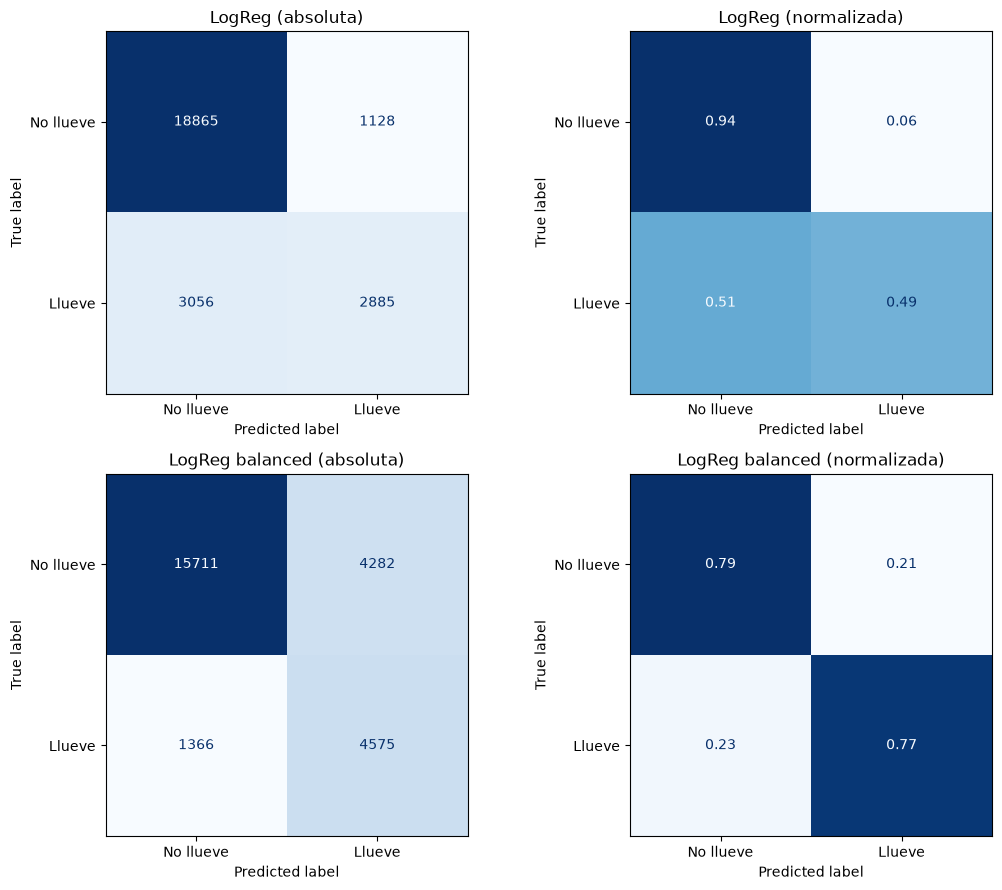

In [25]:
# Matrices de confusión en test, en valores absolutos y normalizadas por fila (cada fila
# suma 1: la diagonal es el recall de cada clase).
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for fila, (nombre, modelo) in enumerate([("LogReg", logreg), ("LogReg balanced", logreg_bal)]):
    pred = modelo.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No llueve", "Llueve"],
                                            cmap="Blues", ax=axes[fila, 0], colorbar=False)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No llueve", "Llueve"],
                                            normalize="true", values_format=".2f",
                                            cmap="Blues", ax=axes[fila, 1], colorbar=False)
    axes[fila, 0].set_title(f"{nombre} (absoluta)")
    axes[fila, 1].set_title(f"{nombre} (normalizada)")
plt.tight_layout()
plt.show()

- **LogReg sin pesos:** acierta el 94% de los días sin lluvia, pero detecta solo el 49% de
  los días con lluvia. Uno de cada dos días de lluvia queda como **falso negativo**. Es el
  sesgo que se esperaba por el desbalance: ante la duda, el modelo predice la clase
  mayoritaria.
- **LogReg balanced:** el recall de la clase positiva sube al 77%, a cambio de que el
  acierto en los días secos baje del 94% al 79%. Los falsos negativos se reducen a menos
  de la mitad, pero aumentan los **falsos positivos**: la precision cae de 0.72 a 0.52, es
  decir que una de cada dos alarmas de lluvia es falsa.

Ninguno de los dos es "mejor" en abstracto: depende de qué error sea más caro. En un
pronóstico de lluvia preferimos no perder los días de lluvia sin que las alarmas falsas
se disparen. Ese equilibrio es el que mide el F1, que sube de 0.58 a 0.62 con los pesos.

### 3.3 Curvas ROC y elección del umbral

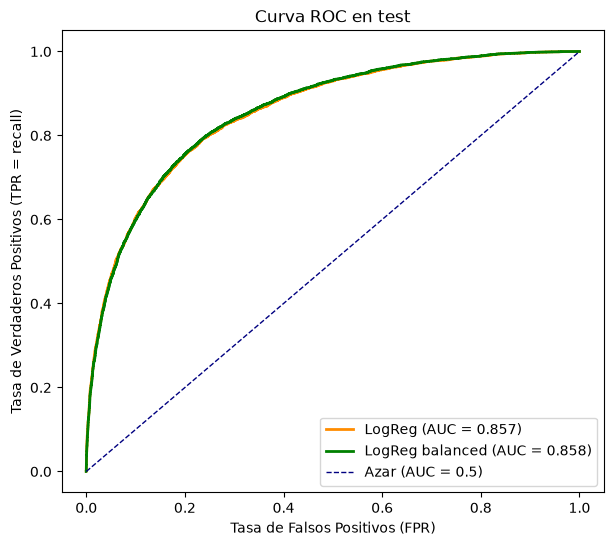

In [26]:
# Curvas ROC en test de los dos modelos. Cada punto de la curva es un umbral distinto.
plt.figure(figsize=(7, 6))
for nombre, modelo, color in [("LogReg", logreg, "darkorange"), ("LogReg balanced", logreg_bal, "green")]:
    proba = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Azar (AUC = 0.5)")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR = recall)")
plt.title("Curva ROC en test")
plt.legend(loc="lower right")
plt.show()

Las dos curvas prácticamente se superponen (AUC de 0.857 y 0.858). `class_weight`
desplaza las probabilidades hacia arriba, pero casi no cambia el **orden** de los días
según su probabilidad, que es lo que mide la curva ROC. Los dos modelos discriminan igual
de bien; lo que cambia es dónde cae el umbral de 0.5 sobre la curva.

El umbral 0.5 es el valor por defecto de `predict`, no el óptimo. Lo elegimos sobre el
conjunto de **validación** (2015), nunca sobre test, porque elegir el umbral también es
ajustar el modelo. Probamos dos criterios:

- **Índice de Youden:** el umbral que maximiza $J = TPR - FPR$, que es el punto de la curva
  ROC más alejado de la diagonal. Da la misma importancia a ambos tipos de error.
- **Máximo F1:** el umbral que maximiza el F1 de la clase positiva, es decir el mejor
  equilibrio entre precision y recall.

Usamos el modelo sin pesos. Mover el umbral cumple la misma función que `class_weight`,
y conviene ver cuál de los dos caminos rinde más.

In [27]:
# Probabilidades del modelo sin pesos sobre validación.
proba_val = logreg.predict_proba(X_val)[:, 1]

# Youden: maximiza TPR - FPR sobre todos los umbrales de la curva ROC.
fpr_v, tpr_v, umbrales_roc = roc_curve(y_val, proba_val)
umbral_youden = umbrales_roc[np.argmax(tpr_v - fpr_v)]

# Máximo F1: precision_recall_curve devuelve un umbral menos que puntos (el último punto
# no tiene umbral), por eso se descarta el último valor de precision y recall.
prec_v, rec_v, umbrales_pr = precision_recall_curve(y_val, proba_val)
f1_v = 2 * prec_v[:-1] * rec_v[:-1] / (prec_v[:-1] + rec_v[:-1] + 1e-12)
umbral_f1 = umbrales_pr[np.argmax(f1_v)]

print(f"Umbral Youden : {umbral_youden:.3f}")
print(f"Umbral max F1 : {umbral_f1:.3f}")

Umbral Youden : 0.190
Umbral max F1 : 0.270


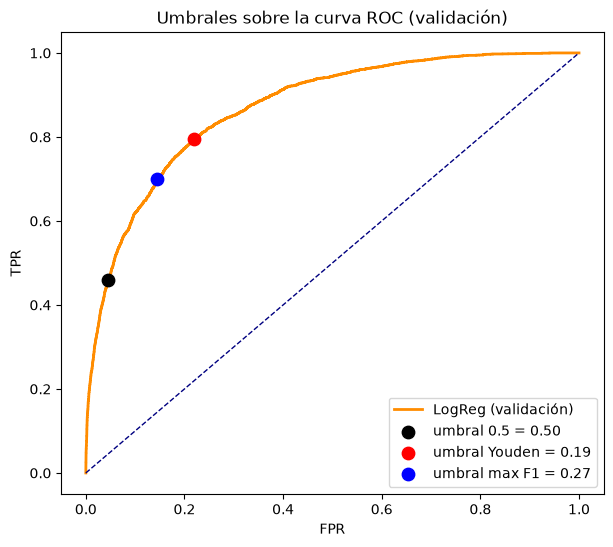

In [28]:
# Ubicamos los tres umbrales sobre la curva ROC de validación.
plt.figure(figsize=(7, 6))
plt.plot(fpr_v, tpr_v, color="darkorange", lw=2, label="LogReg (validación)")
for umbral, color, etiqueta in [(0.5, "black", "0.5"), (umbral_youden, "red", "Youden"), (umbral_f1, "blue", "max F1")]:
    i = np.argmin(np.abs(umbrales_roc - umbral))
    plt.scatter(fpr_v[i], tpr_v[i], color=color, s=80, zorder=3, label=f"umbral {etiqueta} = {umbral:.2f}")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Umbrales sobre la curva ROC (validación)")
plt.legend(loc="lower right")
plt.show()

In [29]:
# Evaluación en test con los umbrales elegidos en validación.
proba_test = logreg.predict_proba(X_test)[:, 1]
for etiqueta, umbral in [("Youden", umbral_youden), ("max F1", umbral_f1)]:
    pred = (proba_test >= umbral).astype(int)
    resultados.append(evaluar(f"LogReg umbral {etiqueta} ({umbral:.2f})", "test", y_test, pred, proba_test))

tabla_test = pd.DataFrame(resultados).query("conjunto == 'test'").drop(columns="conjunto")
display(tabla_test.round(3))

,modelo,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
1,LogReg,0.839,0.715,0.719,0.486,0.580,0.857,0.678
3,LogReg balanced,0.782,0.778,0.517,0.770,0.618,0.858,0.675
4,LogReg umbral Youden (0.19),0.747,0.772,0.470,0.817,0.597,0.857,0.678
5,LogReg umbral max F1 (0.27),0.801,0.774,0.551,0.723,0.625,0.857,0.678


- Los dos umbrales elegidos en validación son mucho menores que 0.5 (0.19 y 0.27). Esto
  confirma que **0.5 no es el mejor umbral** para este problema: con solo un 22% de días
  de lluvia, el modelo rara vez le asigna a la lluvia probabilidades altas.
- **Youden (0.19)** logra el mayor recall (82%), pero con más falsos positivos (precision
  de 0.47).
- **Máximo F1 (0.27)** obtiene el mejor F1 en test de todos los modelos (0.625), con un
  recall del 72% y una precision de 0.55. Es un equilibrio razonable para un pronóstico de
  lluvia.
- Mover el umbral del modelo sin pesos rinde un poco más que entrenar con
  `class_weight="balanced"` (F1 de 0.618), y no requiere reentrenar. Las dos estrategias
  atacan el mismo problema.
- ROC-AUC y PR-AUC no cambian al mover el umbral, porque se calculan sobre las
  probabilidades y no sobre las predicciones.

### 3.4 ¿Conseguimos un buen fitting?

In [30]:
# Comparación train vs test del modelo sin pesos. Una brecha grande indicaría sobreajuste;
# valores bajos en ambos, subajuste.
comparacion = pd.DataFrame(resultados).query("modelo in ['LogReg', 'LogReg balanced']")
display(comparacion.set_index(["modelo", "conjunto"]).round(3))

accuracy  balanced_acc  precision  recall     f1  \
modelo          conjunto                                                     
LogReg          train        0.848         0.731      0.727   0.518  0.605   
                test         0.839         0.715      0.719   0.486  0.580   
LogReg balanced train        0.792         0.788      0.526   0.780  0.628   
                test         0.782         0.778      0.517   0.770  0.618   

                          roc_auc  pr_auc  
modelo          conjunto                   
LogReg          train       0.873   0.702  
                test        0.857   0.678  
LogReg balanced train       0.873   0.700  
                test        0.858   0.675

Consideramos que el ajuste es bueno para un modelo lineal, con algo de subajuste:

- **No hay sobreajuste.** La diferencia entre train y test es chica en todas las métricas
  (ROC-AUC de 0.873 contra 0.857, F1 de 0.605 contra 0.580). Con unas 99 mil filas y 56
  columnas, un modelo lineal regularizado tiene pocos parámetros en relación con los datos
  y no puede memorizarlos.
- **Hay cierto subajuste.** El modelo tampoco llega a valores altos en train (F1 de 0.61),
  así que el límite parece estar en el modelo y no en la cantidad de datos. La regresión
  logística solo puede trazar una frontera lineal (un hiperplano). Relaciones como la
  interacción entre humedad y presión no son lineales.
- La pequeña caída en test también puede deberse a que el test es un período posterior
  (2016–2017), con condiciones algo distintas a las del entrenamiento. Es la misma
  situación que va a enfrentar el modelo en producción.

En la próxima entrega se puede mejorar con la optimización de hiperparámetros (la
regularización `C`) y con la red neuronal, que puede capturar relaciones no lineales.

## 4. Modelos base

Un modelo base es un modelo ingenuo que no aprende casi nada. Sirve como punto de
partida: cualquier modelo que desarrollemos tiene que ganarle, y por un margen que valga
la pena. Implementamos dos:

- **Por mayoría** (`DummyClassifier(strategy="most_frequent")`): predice siempre
  "no llueve". Es el baseline más útil en un problema desbalanceado, porque muestra cuánto
  vale la accuracy "gratis".
- **Persistencia:** "mañana llueve si hoy llovió". Es el equivalente, para series de
  tiempo, de predecir el último valor observado. Usa una sola variable y ninguna cuenta,
  y aun así es un pronóstico razonable.

In [31]:
# Modelo base por mayoría. No usa las variables, así que no necesita preprocesamiento.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
resultados.append(evaluar("Base: mayoría", "test", y_test, dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1]))

# Modelo base de persistencia: la predicción es RainToday. Si RainToday falta, se asume que
# hoy no llovió (es la clase más frecuente). No tiene probabilidades, así que tampoco tiene
# ROC-AUC ni PR-AUC.
pred_persistencia = X_test["RainToday"].fillna(0).astype(int)
resultados.append(evaluar("Base: persistencia", "test", y_test, pred_persistencia))

tabla_test = pd.DataFrame(resultados).query("conjunto == 'test'").drop(columns="conjunto")
display(tabla_test.round(3))

,modelo,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
1,LogReg,0.839,0.715,0.719,0.486,0.580,0.857,0.678
3,LogReg balanced,0.782,0.778,0.517,0.770,0.618,0.858,0.675
4,LogReg umbral Youden (0.19),0.747,0.772,0.470,0.817,0.597,0.857,0.678
5,LogReg umbral max F1 (0.27),0.801,0.774,0.551,0.723,0.625,0.857,0.678
6,Base: mayoría,0.771,0.500,0.000,0.000,0.000,0.500,0.229
7,Base: persistencia,0.748,0.641,0.450,0.444,0.447,NaN,NaN


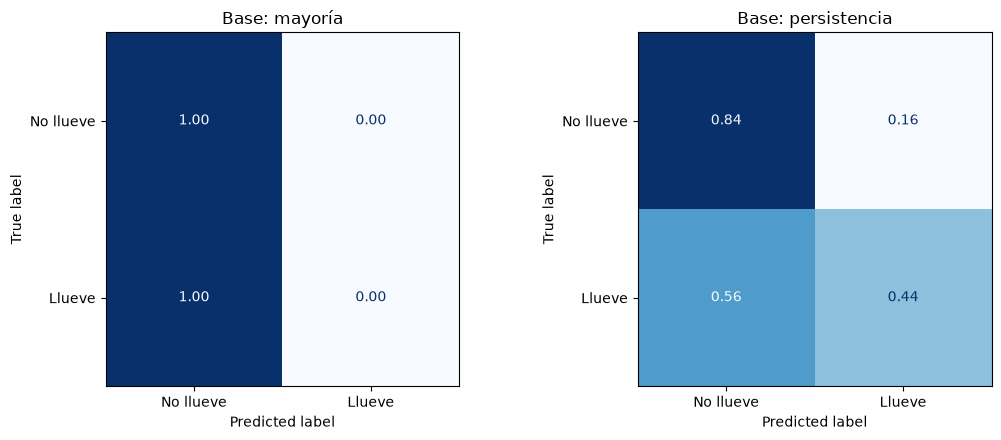

In [32]:
# Matrices de confusión de los modelos base, normalizadas por fila.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nombre, pred) in zip(axes, [("Base: mayoría", dummy.predict(X_test)),
                                     ("Base: persistencia", pred_persistencia)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No llueve", "Llueve"],
                                            normalize="true", values_format=".2f",
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

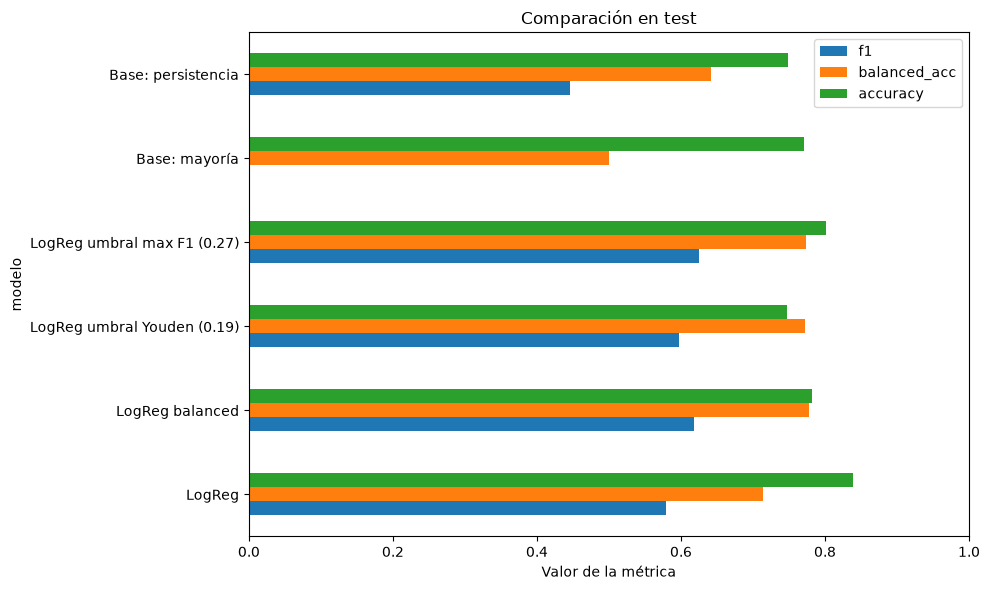

In [33]:
# Comparación gráfica en test: F1 y balanced accuracy de todos los modelos.
tabla_test.set_index("modelo")[["f1", "balanced_acc", "accuracy"]].plot.barh(figsize=(10, 6))
plt.title("Comparación en test")
plt.xlabel("Valor de la métrica")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

- **Base por mayoría:** obtiene 77.1% de accuracy, apenas 7 puntos menos que la regresión
  logística sin pesos, sin haber aprendido nada. Pero su recall, su precision y su F1 valen
  0, y su balanced accuracy y su ROC-AUC valen 0.5, el equivalente al azar. Es la prueba
  práctica de por qué la accuracy no sirve como métrica principal en este dataset.
- **Base por persistencia:** con una sola variable alcanza un F1 de 0.447 y detecta el 44%
  de los días de lluvia. Es un piso más exigente que el de mayoría.
- **La regresión logística supera a los dos con margen.** Su mejor versión (umbral de
  máximo F1) llega a un F1 de 0.625 contra 0.447 de la persistencia, y a una balanced
  accuracy de 0.774 contra 0.641. El modelo aporta información real, más allá de "si hoy
  llovió, mañana también".

Para comparar todos los modelos en el ítem 8 proponemos el **F1 de la clase positiva**. A
diferencia de la accuracy, no se deja engañar por el desbalance, castiga tanto los
falsos negativos como los falsos positivos, y se puede calcular para cualquier modelo,
incluso para los que no dan probabilidades, como la regla de persistencia.